In [6]:
import sys
import os
import torch

print("Python:", sys.executable)
print("Thư mục:", os.getcwd())
print("Kaggle runtime:", os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: /usr/bin/python3
Thư mục: /kaggle/working
Kaggle runtime: Interactive
CUDA: True
GPU: Tesla T4


In [7]:
from kaggle_secrets import UserSecretsClient

token = UserSecretsClient().get_secret("HF_TOKEN")
print("Đã đọc HF_TOKEN:", bool(token))

Đã đọc HF_TOKEN: True


In [8]:
%pip install -q huggingface_hub

from pathlib import Path
import zipfile
from huggingface_hub import hf_hub_download
from kaggle_secrets import UserSecretsClient

token = UserSecretsClient().get_secret("HF_TOKEN")

zip_path = hf_hub_download(
    repo_id="deepghs/nsfw_detect",
    filename="nsfw_dataset_v1.zip",
    repo_type="dataset",
    token=token,
)

extract_dir = Path("/kaggle/working/nsfw_dataset")
dataset_dir = extract_dir / "nsfw_dataset_v1"

extract_dir.mkdir(parents=True, exist_ok=True)

if not dataset_dir.exists():
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(extract_dir)

labels = ["drawings", "hentai", "neutral", "porn", "sexy"]

for label in labels:
    folder = dataset_dir / label
    if not folder.is_dir():
        raise FileNotFoundError(f"Thiếu thư mục: {folder}")
    print(f"{label}: {len(list(folder.glob('*.jpg')))} ảnh JPG")

Note: you may need to restart the kernel to use updated packages.
drawings: 5600 ảnh JPG
hentai: 5600 ảnh JPG
neutral: 5600 ảnh JPG
porn: 5600 ảnh JPG
sexy: 5600 ảnh JPG


## Đánh giá 3 model trên cùng benchmark

Chạy các cell bên dưới theo thứ tự sau khi cell tải dataset đã thành công.
Các model: **NudeNet-320n**, **OpenNSFW2**, **MobileNetV2 NSFW của GantMan**.

Giữ quy ước của nhóm: `porn`, `hentai`, `sexy` là NSFW; `neutral`, `drawings`
là SFW. Đây là benchmark **NSFW cấp ảnh**, chưa phải ground truth nude riêng
hay benchmark bounding box. Không chọn ngưỡng trên tập test này.

Batch mặc định bằng 1 để đo độ trễ từng ảnh trên cùng thiết bị. Thời gian đo
bao gồm đọc ảnh, tiền xử lý, suy luận và hậu xử lý; không gồm cài thư viện,
tải trọng số, tải dataset, kiểm tra ảnh và chạy khởi động. Mỗi model lưu CSV
riêng để có thể xem kết quả từng phần nếu cell sau gặp lỗi.

In [9]:
import importlib
import importlib.metadata as metadata
import subprocess
import sys

# Cài trong kernel Kaggle hiện tại. Không cài nsfw-detector/tensorflow_hub cũ.
# MobileNetV2 sẽ được nạp trực tiếp từ SavedModel của tác giả.
requirements = [
    "tensorflow>=2.20,<2.22", "opennsfw2[keras3]==0.19.0",
    "numpy>=1.26,<2.3", "pandas", "scikit-learn", "matplotlib",
    "Pillow", "opencv-python>=4.10,<5", "psutil", "tqdm", "requests",
]
watched_modules = {"numpy": "numpy", "pandas": "pandas", "tensorflow": "tensorflow",
                   "Pillow": "PIL", "scikit-learn": "sklearn", "scipy": "scipy"}
loaded_versions = {package: metadata.version(package)
                   for package, module in watched_modules.items() if module in sys.modules}
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *requirements])

# NudeNet khai báo onnxruntime CPU. Cài --no-deps để chọn đúng runtime GPU,
# tránh cài song song hai package cùng cung cấp module onnxruntime.
USE_GPU = True  # Đổi False nếu chủ động đo toàn bộ model trên CPU.
runtime_package = "onnxruntime-gpu" if USE_GPU else "onnxruntime"
opposite_package = "onnxruntime" if USE_GPU else "onnxruntime-gpu"
try:
    metadata.version(opposite_package)
except metadata.PackageNotFoundError:
    pass
else:
    if "onnxruntime" in sys.modules:
        raise RuntimeError("ONNX Runtime đã được import. Restart kernel rồi chạy lại từ đầu.")
    subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", opposite_package])
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet",
    f"{runtime_package}>=1.21,<1.24",
])
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", "nudenet==3.4.2",
])
importlib.invalidate_caches()
changed = [package for package, previous in loaded_versions.items()
           if metadata.version(package) != previous]
if changed:
    raise RuntimeError(
        f"Đã cập nhật thư viện đang được dùng: {changed}. Restart kernel rồi chạy lại từ đầu; "
        "dataset đã tải vẫn có trong /kaggle/working của phiên hiện tại."
    )
print("Đã cài thư viện. Nếu kernel báo thư viện đang dùng đã thay đổi, restart rồi chạy lại.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.5/300.5 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 100.0 MB/s eta 0:00:00
Đã cài thư viện. Nếu kernel báo thư viện đang dùng đã thay đổi, restart rồi chạy lại.


In [10]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["OPENNSFW2_KERAS"] = "keras3"
os.environ.setdefault("TF_FORCE_GPU_ALLOW_GROWTH", "true")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import gc
import hashlib
import json
import random
import time
from pathlib import Path
import numpy as np
import pandas as pd
import psutil
from PIL import Image
from IPython.display import display
import torch
import onnxruntime as ort
import tensorflow as tf

BASE_DIR = Path("/kaggle/working")
DATASET_DIR = BASE_DIR / "nsfw_dataset" / "nsfw_dataset_v1"
BENCHMARK_PATH = BASE_DIR / "benchmark_2000.csv"
OUTPUT_DIR = BASE_DIR / "nude_benchmark_results"
MODEL_DIR = BASE_DIR / "nude_benchmark_models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
os.environ["OPENNSFW2_HOME"] = str(MODEL_DIR / "opennsfw2")

LABELS = ["drawings", "hentai", "neutral", "porn", "sexy"]
NSFW_LABELS = {"porn", "hentai", "sexy"}
SAMPLES_PER_CLASS = 400
SEED = 42
BATCH_SIZE = 1
WARMUP_BATCHES = 3
RECREATE_BENCHMARK = False  # Mặc định dùng lại CSV sẵn có để giữ đúng ảnh.
THRESHOLDS = {"NudeNet-320n": 0.5, "OpenNSFW2": 0.5, "MobileNetV2-NSFW": 0.5}

# Chỉ các vùng nhạy cảm lộ rõ được tính vào điểm nude; không dùng mặt/bụng/chân.
NUDE_CLASSES = {
    "FEMALE_BREAST_EXPOSED", "FEMALE_GENITALIA_EXPOSED",
    "MALE_GENITALIA_EXPOSED", "BUTTOCKS_EXPOSED", "ANUS_EXPOSED",
}

tf_gpus = tf.config.list_physical_devices("GPU")
for gpu in tf_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        raise RuntimeError("TensorFlow đã khởi tạo GPU. Restart kernel để cấu hình memory growth.") from exc
if USE_GPU and (not torch.cuda.is_available() or not tf_gpus):
    raise RuntimeError(
        "Cần cả CUDA PyTorch và GPU TensorFlow cho phép đo GPU. "
        "Kiểm tra accelerator/thư viện CUDA; hoặc đặt USE_GPU=False ở cell cài đặt để đo CPU."
    )
TF_DEVICE = "/GPU:0" if USE_GPU else "/CPU:0"
if USE_GPU:
    # PyTorch và ORT dùng CUDA/cuDNN cùng major version; preload trước khi tạo session.
    if hasattr(ort, "preload_dlls"):
        ort.preload_dlls()
    if "CUDAExecutionProvider" not in ort.get_available_providers():
        raise RuntimeError("ORT chưa có CUDAExecutionProvider. Restart kernel sau khi cài onnxruntime-gpu.")

run_results = {}
run_stats = {}
versions = {}
for package in ["torch", "tensorflow", "keras", runtime_package, "opennsfw2", "nudenet",
                "numpy", "pandas", "scikit-learn", "Pillow"]:
    versions[package] = metadata.version(package)
environment = {
    "python": sys.version, "packages": versions, "use_gpu": USE_GPU,
    "gpu": torch.cuda.get_device_name(0) if USE_GPU else None,
    "tf_device": TF_DEVICE, "ort_available_providers": ort.get_available_providers(),
    "batch_size": BATCH_SIZE, "warmup_batches": WARMUP_BATCHES,
    "thresholds": THRESHOLDS, "nsfw_labels": sorted(NSFW_LABELS),
    "nudenet_classes": sorted(NUDE_CLASSES),
    "dataset_repo": "deepghs/nsfw_detect", "dataset_filename": "nsfw_dataset_v1.zip",
    "dataset_revision": Path(zip_path).parent.name if "zip_path" in globals() else None,
}
(OUTPUT_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Thiết bị:", environment["gpu"] or "CPU")
display(pd.DataFrame(versions.items(), columns=["package", "version"]))
print("Kết quả:", OUTPUT_DIR)


Thiết bị: Tesla T4


,package,version
0,torch,2.11.0+cu128
1,tensorflow,2.20.0
2,keras,3.13.2
3,onnxruntime-gpu,1.23.2
4,opennsfw2,0.19.0
5,nudenet,3.4.2
6,numpy,2.1.3
7,pandas,2.3.3
8,scikit-learn,1.6.1
9,Pillow,12.3.0


Kết quả: /kaggle/working/nude_benchmark_results


### Tạo hoặc đọc lại benchmark, kiểm tra dữ liệu

Giữ nguyên cách lấy mẫu của notebook nhóm: sắp xếp tên file JPG, lấy 400 ảnh/lớp
bằng `random.Random(42)`, rồi xáo trộn bằng pandas với seed 42. Nếu CSV đã có,
đọc lại CSV đó. Kiểm tra ảnh trước khi đo; không âm thầm bỏ ảnh lỗi.

In [11]:
if BENCHMARK_PATH.exists() and not RECREATE_BENCHMARK:
    benchmark_df = pd.read_csv(BENCHMARK_PATH)
    print("Dùng lại:", BENCHMARK_PATH)
else:
    rng = random.Random(SEED)
    rows = []
    for label in LABELS:
        paths = sorted((DATASET_DIR / label).glob("*.jpg"))
        if len(paths) < SAMPLES_PER_CLASS:
            raise ValueError(f"{label}: có {len(paths)} JPG, cần {SAMPLES_PER_CLASS}. Kiểm tra cell tải dữ liệu.")
        for path in rng.sample(paths, SAMPLES_PER_CLASS):
            rows.append({"image_path": str(path), "true_label": label})
    benchmark_df = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
    benchmark_df.to_csv(BENCHMARK_PATH, index=False)

required = {"image_path", "true_label"}
if not required.issubset(benchmark_df.columns):
    raise ValueError(f"Benchmark thiếu cột: {required - set(benchmark_df.columns)}")
benchmark_df = benchmark_df[["image_path", "true_label"]].copy().reset_index(drop=True)
benchmark_df["true_label"] = benchmark_df["true_label"].astype(str).str.strip().str.lower()
if benchmark_df["image_path"].duplicated().any():
    raise ValueError("Benchmark có đường dẫn trùng.")
counts = benchmark_df["true_label"].value_counts().to_dict()
if counts != {label: SAMPLES_PER_CLASS for label in LABELS}:
    raise ValueError(f"Benchmark cần {SAMPLES_PER_CLASS} ảnh/lớp; số lượng hiện tại: {counts}")

audit_rows = []
for row in benchmark_df.itertuples(index=False):
    path = Path(row.image_path)
    if not path.is_file():
        raise FileNotFoundError(f"Ảnh trong CSV không tồn tại: {path}")
    image_id = path.resolve().relative_to(DATASET_DIR.resolve()).as_posix()
    with Image.open(path) as image:
        image.load()
        width, height = image.size
    audit_rows.append({
        "image_id": image_id, "width": width, "height": height,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    })
audit_df = pd.DataFrame(audit_rows)
benchmark_df = pd.concat([benchmark_df, audit_df], axis=1)
benchmark_df["y_true"] = benchmark_df["true_label"].isin(NSFW_LABELS).astype(int)
signature = "\n".join(
    f"{row.image_id}|{row.true_label}|{row.sha256}" for row in benchmark_df.itertuples(index=False)
)
BENCHMARK_SHA256 = hashlib.sha256(signature.encode()).hexdigest()
benchmark_df.to_csv(OUTPUT_DIR / "benchmark_audit.csv", index=False)
conflicting = benchmark_df.groupby("sha256")["true_label"].nunique().gt(1).sum()
if conflicting:
    raise ValueError(f"Có {conflicting} nhóm ảnh giống hệt nhưng khác nhãn; xem benchmark_audit.csv.")
print("Ảnh hợp lệ:", len(benchmark_df))
print("Ảnh trùng nội dung (không tự bỏ):", int(benchmark_df["sha256"].duplicated().sum()))
print("Benchmark SHA256:", BENCHMARK_SHA256)
display(benchmark_df.groupby("true_label").agg(n_images=("image_id", "size"),
                                                min_width=("width", "min"),
                                                min_height=("height", "min")))
print("NSFW:", int(benchmark_df.y_true.sum()), "| SFW:", int((benchmark_df.y_true == 0).sum()))


Ảnh hợp lệ: 2000
Ảnh trùng nội dung (không tự bỏ): 0
Benchmark SHA256: 261b3cca292d7cd6b31ba92ac20ad93c7336c11bb7779b2012d48a1104457f3b


,n_images,min_width,min_height
true_label,,,
drawings,400,236,236
hentai,400,305,240
neutral,400,416,270
porn,400,443,480
sexy,400,394,431


NSFW: 1200 | SFW: 800


### Đo tốc độ và tính metric

Ngưỡng mặc định 0,5 là baseline cố định. `PR_AUC_AP` là Average Precision.
Điểm NudeNet là max confidence của các vùng đã chọn, bằng 0 khi không phát hiện;
đây không phải xác suất NSFW đã hiệu chỉnh. Bộ hậu xử lý NudeNet có ngưỡng nội bộ,
nên AUC của nó được tính trên điểm sau hậu xử lý.

`mean_ms_per_image` và `images_per_second` lấy từ tổng thời gian các batch;
`wall_seconds` còn tính cả ghi nhận kết quả/progress. p50/p95 cấp ảnh chỉ có khi
batch thực tế bằng 1. RAM là RSS của tiến trình sau khi chạy, không phải peak.

In [12]:
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def calculate_metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if scores.shape != y_true.shape or not len(y_true):
        raise ValueError("Số score không khớp số nhãn hoặc dữ liệu rỗng.")
    if not np.isin(y_true, [0, 1]).all() or not 0 <= threshold <= 1:
        raise ValueError("Nhãn phải là 0/1 và ngưỡng phải nằm trong [0, 1].")
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Score cần hữu hạn và nằm trong [0, 1].")
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    has_two_classes = len(np.unique(y_true)) == 2
    return {
        "n_images": len(y_true), "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, scores) if has_two_classes else np.nan,
        "PR_AUC_AP": average_precision_score(y_true, scores) if has_two_classes else np.nan,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

def nudenet_score(detections, allowed_classes):
    return max((float(item["score"]) for item in detections
                if item["class"] in allowed_classes), default=0.0)

def synchronize_device():
    if USE_GPU:
        torch.cuda.synchronize()
    # Adapter TensorFlow gọi .numpy(); ORT session.run trả output CPU đồng bộ.

def benchmark_model(name, predict_batch, model_info, effective_batch_size=None):
    batch_size = effective_batch_size or BATCH_SIZE
    if batch_size < 1:
        raise ValueError("Batch size phải >= 1.")
    threshold = THRESHOLDS[name]
    paths = benchmark_df["image_path"].tolist()
    warmup_paths = paths[:batch_size]
    print(f"{name}: warm-up {WARMUP_BATCHES} lần; batch={batch_size}; device={model_info['device']}")
    for _ in range(WARMUP_BATCHES):
        predict_batch(warmup_paths)
    synchronize_device()

    batches = []
    predictions = []
    wall_start = time.perf_counter()
    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]
        synchronize_device()
        tick = time.perf_counter()
        batch_predictions = predict_batch(batch_paths)
        synchronize_device()
        elapsed = time.perf_counter() - tick
        if len(batch_predictions) != len(batch_paths):
            raise ValueError(f"{name}: số kết quả batch không khớp số ảnh.")
        batches.append({"batch_start": start, "n_images": len(batch_paths), "seconds": elapsed})
        predictions.extend(batch_predictions)
        if len(predictions) % 200 == 0 or len(predictions) == len(paths):
            print(f"  {len(predictions)}/{len(paths)}")
    wall_seconds = time.perf_counter() - wall_start
    frame = benchmark_df[["image_id", "image_path", "true_label", "y_true"]].copy()
    pred_frame = pd.DataFrame(predictions)
    if "score" not in pred_frame:
        raise ValueError(f"{name}: adapter thiếu cột score.")
    metrics = calculate_metrics(frame["y_true"], pred_frame["score"], threshold)
    frame = pd.concat([frame, pred_frame], axis=1)
    frame["y_pred"] = (frame["score"] >= threshold).astype(int)
    frame["model"] = name
    frame["benchmark_sha256"] = BENCHMARK_SHA256
    timing_df = pd.DataFrame(batches)
    measured_seconds = float(timing_df["seconds"].sum())
    stats = {
        "model": name, **metrics, **model_info,
        "batch_size": batch_size, "measured_seconds": measured_seconds,
        "wall_seconds": wall_seconds,
        "mean_ms_per_image": measured_seconds / len(frame) * 1000,
        "images_per_second": len(frame) / measured_seconds,
        "p50_image_ms": float(timing_df.seconds.quantile(.50) * 1000) if batch_size == 1 else np.nan,
        "p95_image_ms": float(timing_df.seconds.quantile(.95) * 1000) if batch_size == 1 else np.nan,
        "p95_batch_ms": float(timing_df.seconds.quantile(.95) * 1000),
        "process_rss_mb_after": psutil.Process().memory_info().rss / 1024**2,
        "benchmark_sha256": BENCHMARK_SHA256,
    }
    slug = name.lower().replace("-", "_")
    frame.to_csv(OUTPUT_DIR / f"{slug}_predictions.csv", index=False)
    timing_df.to_csv(OUTPUT_DIR / f"{slug}_batch_timings.csv", index=False)
    (OUTPUT_DIR / f"{slug}_metrics.json").write_text(
        json.dumps(stats, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    run_results[name] = frame
    run_stats[name] = stats
    display(pd.DataFrame([stats])[["model", "n_images", "precision", "recall", "f1",
                                    "ROC_AUC", "PR_AUC_AP", "mean_ms_per_image", "images_per_second"]].round(4))
    print("Confusion matrix: hàng=true [SFW, NSFW], cột=predicted [SFW, NSFW]")
    print(np.array([[metrics["TN"], metrics["FP"]], [metrics["FN"], metrics["TP"]]]))
    return frame


### 1. NudeNet-320n

Model ONNX đi kèm `nudenet==3.4.2`. Tạo lại session với provider được chọn vì
một số bản NudeNet không sử dụng tham số `providers` của constructor.
Luôn in provider thực tế; phép đo GPU sẽ dừng nếu session chỉ dùng CPU.
Nguồn: https://github.com/notAI-tech/NudeNet

In [13]:
import importlib.util
from nudenet import NudeDetector

setup_start = time.perf_counter()
nudenet_path = Path(importlib.util.find_spec("nudenet").origin).parent / "320n.onnx"
provider_list = ["CPUExecutionProvider"]
if USE_GPU:
    provider_list = [
        ("CUDAExecutionProvider", {"device_id": 0, "gpu_mem_limit": 2 * 1024**3,
                                   "arena_extend_strategy": "kSameAsRequested"}),
        "CPUExecutionProvider",
    ]
# __new__ tránh tạo một CPU session không cần thiết trong constructor của NudeNet.
detector = NudeDetector.__new__(NudeDetector)
detector.onnx_session = ort.InferenceSession(str(nudenet_path), providers=provider_list)
detector.input_width = detector.input_height = 320
detector.input_name = detector.onnx_session.get_inputs()[0].name
actual_providers = detector.onnx_session.get_providers()
print("NudeNet providers:", actual_providers)
if USE_GPU and "CUDAExecutionProvider" not in actual_providers:
    raise RuntimeError("NudeNet đang fallback CPU. Sửa CUDA/ORT trước khi so sánh tốc độ GPU.")

def predict_nudenet(paths):
    records = []
    for path in paths:
        detections = detector.detect(path)
        records.append({
            "score": nudenet_score(detections, NUDE_CLASSES),
            "detections_json": json.dumps(detections, ensure_ascii=False),
        })
    return records

nudenet_info = {
    "device": "CUDAExecutionProvider" if USE_GPU else "CPUExecutionProvider",
    "setup_seconds": time.perf_counter() - setup_start,
    "checkpoint_mb": nudenet_path.stat().st_size / 1024**2,
    "checkpoint_sha256": file_sha256(nudenet_path),
    "checkpoint": "nudenet==3.4.2/320n.onnx",
    "parameters": None,
}
nudenet_results = benchmark_model("NudeNet-320n", predict_nudenet, nudenet_info, effective_batch_size=1)
del detector
gc.collect()


NudeNet providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
NudeNet-320n: warm-up 3 lần; batch=1; device=CUDAExecutionProvider
  200/2000
  400/2000
  600/2000
  800/2000
  1000/2000
  1200/2000
  1400/2000
  1600/2000
  1800/2000
  2000/2000


,model,n_images,precision,recall,f1,ROC_AUC,PR_AUC_AP,mean_ms_per_image,images_per_second
0,NudeNet-320n,2000,0.9793,0.4733,0.6382,0.7703,0.8221,17.3158,57.7508


Confusion matrix: hàng=true [SFW, NSFW], cột=predicted [SFW, NSFW]
[[788  12]
 [632 568]]


60

### 2. OpenNSFW2

Dùng preprocessing **YAHOO** của tác giả (resize, JPEG round-trip, center crop,
BGR và trừ mean). Giữ đầy đủ preprocessing trong thời gian đo.
Nguồn: https://github.com/bhky/opennsfw2

In [14]:
import opennsfw2 as n2

setup_start = time.perf_counter()
open_weights = MODEL_DIR / "opennsfw2" / "weights" / "open_nsfw_weights.h5"
with tf.device(TF_DEVICE):
    open_model = n2.make_open_nsfw_model(weights_path=str(open_weights))

def predict_opennsfw(paths):
    images = []
    for path in paths:
        with Image.open(path) as image:
            images.append(n2.preprocess_image(image.convert("RGB"), n2.Preprocessing.YAHOO))
    with tf.device(TF_DEVICE):
        probabilities = open_model(np.stack(images), training=False).numpy()
    return [{"score": float(row[1]), "sfw_score": float(row[0])} for row in probabilities]

open_info = {
    "device": TF_DEVICE, "setup_seconds": time.perf_counter() - setup_start,
    "parameters": int(open_model.count_params()),
    "checkpoint_mb": open_weights.stat().st_size / 1024**2,
    "checkpoint_sha256": file_sha256(open_weights),
    "checkpoint": "Yahoo Open-NSFW / OpenNSFW2 pretrained weights",
}
opennsfw_results = benchmark_model("OpenNSFW2", predict_opennsfw, open_info)
del open_model
tf.keras.backend.clear_session()
gc.collect()


I0000 00:00:1792477703.479319     115 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13750 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792477703.482384     115 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Pre-trained weights will be downloaded.


Downloading...
From: https://github.com/bhky/opennsfw2/releases/download/v0.1.0/open_nsfw_weights.h5
To: /kaggle/working/nude_benchmark_models/opennsfw2/weights/open_nsfw_weights.h5
100%|██████████| 24.2M/24.2M [00:00<00:00, 197MB/s]


OpenNSFW2: warm-up 3 lần; batch=1; device=/GPU:0
  200/2000
  400/2000
  600/2000
  800/2000
  1000/2000
  1200/2000
  1400/2000
  1600/2000
  1800/2000
  2000/2000


,model,n_images,precision,recall,f1,ROC_AUC,PR_AUC_AP,mean_ms_per_image,images_per_second
0,OpenNSFW2,2000,0.9597,0.735,0.8325,0.9428,0.9632,195.5096,5.1148


Confusion matrix: hàng=true [SFW, NSFW], cột=predicted [SFW, NSFW]
[[763  37]
 [318 882]]


0

### 3. MobileNetV2 NSFW — GantMan

Dùng **release 1.2.0, MobileNetV2 1.4 / 224** của tác giả. Link H5 S3 cũ đã
trả 403 khi kiểm tra, nên tải ZIP SavedModel từ GitHub Releases. Nạp bằng
`tf.saved_model.load` để tránh lỗi deserialize model Keras cũ trên Keras 3.
Giữ thứ tự lớp và preprocessing của GantMan: RGB, nearest resize 224×224,
float32 / 255. Score NSFW = `hentai + porn + sexy`.

Nguồn: https://github.com/GantMan/nsfw_model/releases/tag/1.2.0
và https://github.com/GantMan/nsfw_model/blob/master/nsfw_detector/predict.py

In [15]:
import requests
import zipfile

setup_start = time.perf_counter()
MOBILE_URL = "https://github.com/GantMan/nsfw_model/releases/download/1.2.0/mobilenet_v2_140_224.1.zip"
mobile_zip = MODEL_DIR / "mobilenet_v2_140_224.1.zip"
mobile_dir = MODEL_DIR / "mobilenet_v2_140_224_1"
if not mobile_zip.exists():
    partial = mobile_zip.with_suffix(".zip.part")
    with requests.get(MOBILE_URL, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        with partial.open("wb") as handle:
            for chunk in response.iter_content(1024 * 1024):
                handle.write(chunk)
    if not zipfile.is_zipfile(partial):
        raise ValueError("File MobileNet tải về không phải ZIP hợp lệ.")
    partial.replace(mobile_zip)
mobile_dir.mkdir(exist_ok=True)
saved_models = list(mobile_dir.rglob("saved_model.pb"))
if not saved_models:
    with zipfile.ZipFile(mobile_zip) as archive:
        for member in archive.infolist():
            target = (mobile_dir / member.filename).resolve()
            if not target.is_relative_to(mobile_dir.resolve()):
                raise ValueError("ZIP có đường dẫn ngoài thư mục model.")
        archive.extractall(mobile_dir)
    saved_models = list(mobile_dir.rglob("saved_model.pb"))
if len(saved_models) != 1:
    raise ValueError(f"Cần đúng 1 SavedModel trong release, tìm thấy {len(saved_models)}.")
saved_model_dir = saved_models[0].parent
checkpoint_labels = (saved_model_dir / "class_labels.txt").read_text().splitlines()
if checkpoint_labels != LABELS:
    raise ValueError(f"Thứ tự nhãn checkpoint khác LABELS: {checkpoint_labels}")
with tf.device(TF_DEVICE):
    mobile_model = tf.saved_model.load(str(saved_model_dir))
mobile_signature = mobile_model.signatures["serving_default"]
_, input_specs = mobile_signature.structured_input_signature
if len(input_specs) != 1:
    raise ValueError(f"Không nhận diện được input MobileNet: {input_specs}")
mobile_input_name, mobile_input_spec = next(iter(input_specs.items()))
if mobile_input_spec.dtype != tf.float32 or mobile_input_spec.shape.as_list()[1:] != [224, 224, 3]:
    raise ValueError(f"Input MobileNet không khớp RGB float32 224x224: {mobile_input_spec}")
print("MobileNet input:", mobile_input_name, mobile_input_spec)
print("MobileNet outputs:", mobile_signature.structured_outputs)

def predict_mobilenet(paths):
    images = []
    for path in paths:
        with Image.open(path) as image:
            image = image.convert("RGB").resize((224, 224), Image.Resampling.NEAREST)
            images.append(np.asarray(image, dtype=np.float32) / 255.0)
    with tf.device(TF_DEVICE):
        output = mobile_signature(**{mobile_input_name: tf.convert_to_tensor(np.stack(images))})
        if len(output) != 1:
            raise ValueError(f"MobileNet trả nhiều output chưa được xử lý: {list(output)}")
        probabilities = next(iter(output.values())).numpy()
    if probabilities.shape != (len(paths), 5):
        raise ValueError(f"MobileNet cần output [batch,5], nhận {probabilities.shape}")
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-3):
        raise ValueError("MobileNet output không phải xác suất softmax; không tự diễn giải thành score.")
    records = []
    for row in probabilities:
        record = {f"p_{label}": float(value) for label, value in zip(LABELS, row)}
        record["score"] = float(np.clip(row[[1, 3, 4]].sum(), 0, 1))
        records.append(record)
    return records

variables = mobile_signature.variables
mobile_runtime_files = [saved_models[0], *(saved_model_dir / "variables").rglob("*")]
mobile_info = {
    "device": TF_DEVICE, "setup_seconds": time.perf_counter() - setup_start,
    "parameters": int(sum(np.prod(variable.shape) for variable in variables)) if variables is not None else None,
    "checkpoint_mb": sum(path.stat().st_size for path in mobile_runtime_files if path.is_file()) / 1024**2,
    "checkpoint_sha256": file_sha256(mobile_zip), "checkpoint": MOBILE_URL,
}
mobilenet_results = benchmark_model("MobileNetV2-NSFW", predict_mobilenet, mobile_info)
del mobile_model, mobile_signature
tf.keras.backend.clear_session()
gc.collect()


MobileNet input: input TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input')
MobileNet outputs: {'prediction': TensorSpec(shape=(None, 5), dtype=tf.float32, name='prediction')}
MobileNetV2-NSFW: warm-up 3 lần; batch=1; device=/GPU:0
  200/2000
  400/2000
  600/2000
  800/2000
  1000/2000
  1200/2000
  1400/2000
  1600/2000
  1800/2000
  2000/2000


,model,n_images,precision,recall,f1,ROC_AUC,PR_AUC_AP,mean_ms_per_image,images_per_second
0,MobileNetV2-NSFW,2000,0.9507,0.9158,0.9329,0.979,0.9859,8.2883,120.6513


Confusion matrix: hàng=true [SFW, NSFW], cột=predicted [SFW, NSFW]
[[ 743   57]
 [ 101 1099]]


0

### Bảng so sánh và biểu đồ

Bảng tổng hợp chỉ được tạo sau khi đủ cả 3 model và tất cả đều có kết quả
cho đúng từng ảnh trong benchmark. Không dùng inner join để âm thầm bỏ mẫu lỗi.
Nếu dùng batch khác 1, đọc cả cột batch size và thời gian batch khi so tốc độ.

CHẤT LƯỢNG — baseline ngưỡng cố định, không tối ưu trên test


,model,n_images,threshold,accuracy,precision,recall,f1,ROC_AUC,PR_AUC_AP,TN,FP,FN,TP
0,NudeNet-320n,2000,0.5,0.6780,0.9793,0.4733,0.6382,0.7703,0.8221,788,12,632,568
1,OpenNSFW2,2000,0.5,0.8225,0.9597,0.7350,0.8325,0.9428,0.9632,763,37,318,882
2,MobileNetV2-NSFW,2000,0.5,0.9210,0.9507,0.9158,0.9329,0.9790,0.9859,743,57,101,1099


TỐC ĐỘ — đọc ảnh + preprocessing + inference + postprocessing, sau warm-up


,model,device,batch_size,parameters,checkpoint_mb,setup_seconds,measured_seconds,wall_seconds,mean_ms_per_image,p50_image_ms,p95_image_ms,images_per_second,process_rss_mb_after
0,NudeNet-320n,CUDAExecutionProvider,1,NaN,11.587,0.485,34.632,34.663,17.316,17.178,18.977,57.751,1992.086
1,OpenNSFW2,/GPU:0,1,5944514.0,23.099,3.413,391.019,391.057,195.510,194.584,203.597,5.115,2283.066
2,MobileNetV2-NSFW,/GPU:0,1,4372677.0,19.471,3.281,16.577,16.614,8.288,8.255,9.387,120.651,2452.738


THEO NHÃN GỐC — NSFW_prediction_rate là recall trên lớp dương, FPR trên lớp âm


,model,class,n_images,NSFW_prediction_rate,binary_accuracy,mean_score
0,NudeNet-320n,drawings,400,0.0025,0.9975,0.0159
1,NudeNet-320n,hentai,400,0.4275,0.4275,0.3510
2,NudeNet-320n,neutral,400,0.0275,0.9725,0.0296
3,NudeNet-320n,porn,400,0.7100,0.7100,0.5448
4,NudeNet-320n,sexy,400,0.2825,0.2825,0.2339
5,OpenNSFW2,drawings,400,0.0650,0.9350,0.1120
6,OpenNSFW2,hentai,400,0.7725,0.7725,0.7314
7,OpenNSFW2,neutral,400,0.0275,0.9725,0.0587
8,OpenNSFW2,porn,400,0.8975,0.8975,0.8716
9,OpenNSFW2,sexy,400,0.5350,0.5350,0.5413


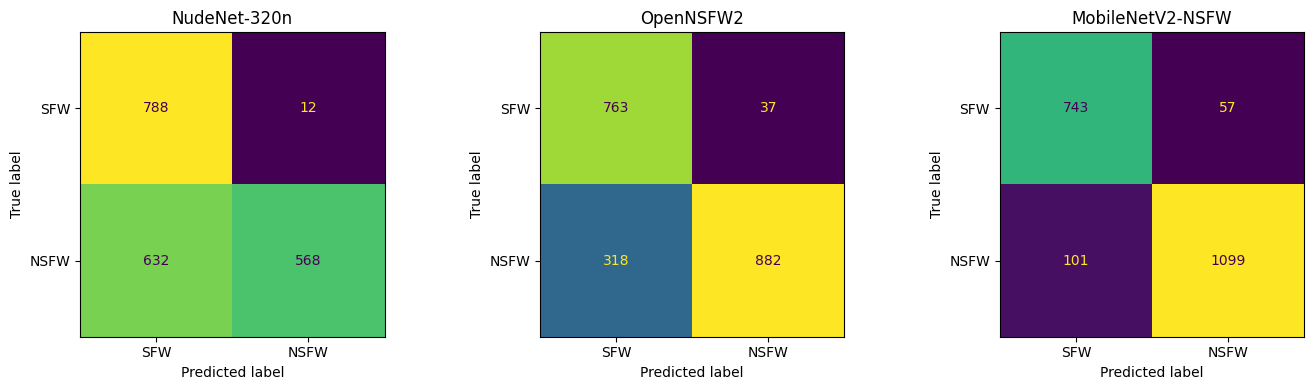

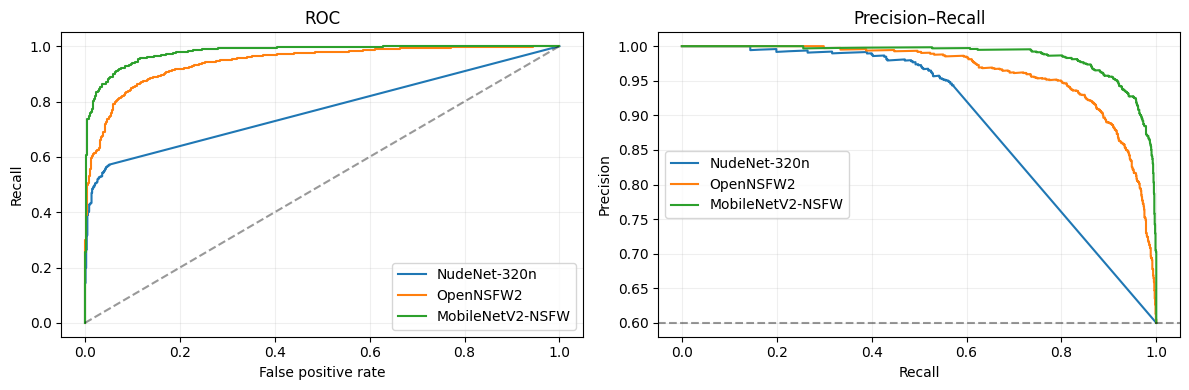

Đã lưu toàn bộ kết quả vào: /kaggle/working/nude_benchmark_results
Để so với notebook nhóm: dùng cùng ảnh, quy ước nhãn, phần cứng và batch size.


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

MODEL_NAMES = ["NudeNet-320n", "OpenNSFW2", "MobileNetV2-NSFW"]
missing = set(MODEL_NAMES) - set(run_results)
if missing:
    raise RuntimeError(f"Chưa đủ kết quả: {sorted(missing)}. Chạy các cell model còn thiếu.")
for name in MODEL_NAMES:
    frame = run_results[name]
    if frame["image_id"].tolist() != benchmark_df["image_id"].tolist():
        raise ValueError(f"{name}: danh sách/thứ tự ảnh không khớp benchmark.")
    if frame["y_true"].tolist() != benchmark_df["y_true"].tolist():
        raise ValueError(f"{name}: ground truth không khớp.")

summary_df = pd.DataFrame([run_stats[name] for name in MODEL_NAMES])
quality_columns = ["model", "n_images", "threshold", "accuracy", "precision", "recall",
                   "f1", "ROC_AUC", "PR_AUC_AP", "TN", "FP", "FN", "TP"]
speed_columns = ["model", "device", "batch_size", "parameters", "checkpoint_mb", "setup_seconds",
                 "measured_seconds", "wall_seconds", "mean_ms_per_image", "p50_image_ms",
                 "p95_image_ms", "images_per_second", "process_rss_mb_after"]
print("CHẤT LƯỢNG — baseline ngưỡng cố định, không tối ưu trên test")
display(summary_df[quality_columns].round(4))
print("TỐC ĐỘ — đọc ảnh + preprocessing + inference + postprocessing, sau warm-up")
display(summary_df[speed_columns].round(3))
summary_df.to_csv(OUTPUT_DIR / "benchmark_summary.csv", index=False)

class_rows = []
merged = benchmark_df[["image_id", "image_path", "true_label", "y_true"]].copy()
for name in MODEL_NAMES:
    frame = run_results[name]
    merged[f"{name}_score"] = frame["score"].to_numpy()
    merged[f"{name}_pred"] = frame["y_pred"].to_numpy()
    for label in LABELS:
        group = frame.loc[frame["true_label"] == label]
        class_rows.append({
            "model": name, "class": label, "n_images": len(group),
            "NSFW_prediction_rate": group["y_pred"].mean(),
            "binary_accuracy": (group["y_pred"] == group["y_true"]).mean(),
            "mean_score": group["score"].mean(),
        })
per_class_df = pd.DataFrame(class_rows)
print("THEO NHÃN GỐC — NSFW_prediction_rate là recall trên lớp dương, FPR trên lớp âm")
display(per_class_df.round(4))
per_class_df.to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)
merged.to_csv(OUTPUT_DIR / "all_model_predictions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, MODEL_NAMES):
    frame = run_results[name]
    matrix = confusion_matrix(frame["y_true"], frame["y_pred"], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["SFW", "NSFW"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in MODEL_NAMES:
    frame = run_results[name]
    fpr, tpr, _ = roc_curve(frame["y_true"], frame["score"])
    precision, recall, _ = precision_recall_curve(frame["y_true"], frame["score"])
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[0].set(xlabel="False positive rate", ylabel="Recall", title="ROC")
axes[1].axhline(benchmark_df.y_true.mean(), color="k", linestyle="--", alpha=.4)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall")
for ax in axes:
    ax.legend()
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "roc_pr_curves.png", dpi=150)
plt.show()
print("Đã lưu toàn bộ kết quả vào:", OUTPUT_DIR)
print("Để so với notebook nhóm: dùng cùng ảnh, quy ước nhãn, phần cứng và batch size.")
